# Exercise 9: Genetic algorithm for the Traveling Salesman Problem
  > ***goal**: write a program that solves the TSP implementing a **genetic algorithm**, then use it for*
  > - 34 cities placed randomly on a circumference
  > - 34 cities placed randomly on inside a square
  >
  > Lastly, plot the results showing
  > 1. a picture of the best path in cartesian coordinates
  > 2. a plot of the (*progressive*) best path's fitness and the average fitness of the top-half population as functions of the generations passed
  

#### Setting the problem and tools

First we set the problem by writing a `City` class and a `TSP` class (containing global parameters of the system such as a cities' list and a matrix of their relative distances, computed only once):


```cpp
/********************************************/
/**************** city class ****************/
/********************************************/

class City {
private:
  std::string _name;
  std::vector<double> _pos{};

public:
  City(const std::string &, const std::vector<double> &);
  const std::string &get_name() const;
  const std::vector<double> &get_pos() const;
};

double distance(const City &, const City &);
std::vector<City> read_cities(const std::string &);
std::vector<std::vector<double>> distances_matrix(const std::vector<City> &);

/********************************************/
/***************** tsp class ****************/
/********************************************/

class TSP {
private:
  std::vector<City> _cities{};
  std::size_t _ncities = 0;
  std::vector<std::vector<double>> _distances_matrix{};

public:
  explicit TSP(const std::vector<City> &);
  explicit TSP(const std::string &);
  std::size_t n() const;
  const City& city(std::size_t) const;
  double d(std::size_t, std::size_t) const;
};
```

Note that each class is equipped with some other external functions that can be useful for solving or testing the algorithm.

Also note that in the computation of the cities distances we are using the simple $\mathrm{L}^{(1)}$ norm, but this can be easily changed in the definitions of `distance_matrix(const std::vector<City>&)` and `void Route::set_length(const TSP&)`.

Then, to implement a Genetic Algorithm, we also write the `Route` and `Population` classes:

```cpp
/********************************************/
/**************** route class ***************/
/********************************************/

class Route {
private:
  std::vector<std::size_t> _order{};
  double _length = 0.0;
  void _set_length(const TSP &);
  void _mutate_swap(const TSP &, Random &),
      _mutate_shift(const TSP &, Random &),
      _mutate_block_swap(const TSP &, Random &),
      _mutate_invert(const TSP &, Random &);
  double _p_swap = 0.05, _p_shift = 0.05, _p_block_swap = 0.05,
         _p_invert = 0.05;

public:
  Route(std::vector<std::size_t>, const TSP &);
  double length() const;
  bool operator<(const Route &) const;
  const std::vector<std::size_t> &order() const;
  void mutate(const TSP &, Random &);
};

/* random index in [min, max) */
std::size_t rnd_index(std::size_t min, std::size_t max, Random &rnd);
/* random order of indices [0, N), always starting from 0 */
std::vector<std::size_t> rnd_order(std::size_t N, Random &rnd);
bool validate_order(std::size_t, const std::vector<std::size_t> &);

void sort(std::vector<Route> &);
double recompute_length(const Route &, const TSP &);

/********************************************/
/************* population class *************/
/********************************************/

class Population {
private:
  std::vector<Route> _routes{};
  std::pair<Route, Route> _crossover(std::size_t, std::size_t,
                                          const TSP &, Random &) const;
  std::pair<Route, Route> _select_and_generate(const TSP &,
                                               Random &) const;
  double _select_weight_pow = 2.0, _p_crossover = 0.6;

public:
  Population(std::size_t, const TSP &, Random &rnd);
  const Route& best() const;
  double best_length() const;
  double half_mean_length() const;
  void check(const TSP&);
  void next_generation(const TSP &, Random &);
};
```

Where methods like `rnd_index(std::size_t, std::size_t)` or the mutation methods make use of the same `Random` class used for the particles simulations to generate random numbers.

For the actual implementation of these classes refer to the *'../tsp_genetic_algorithm/source'* directory in this same repository.

#### Cities generation and main loop

To generate the requested systems (*cites on a circumference and inside a square*) we can write these additional functions:
```cpp
std::vector<City> cities_in_a_square(std::size_t, Random&);
std::vector<City> cities_on_a_circle(std::size_t, Random&);
double circle_optimum(const TSP&);
```

For simplicity, instead of a file-parsing process similar to the one used in the particle simulator, we hardcode the simulation parameters and process directly in the `main()` function:
```cpp
int main() {
  Random rnd("input/seed_in.dat");

  std::size_t ncities = 34;
  std::size_t nroutes = 500;
  std::size_t ngens = 1000;
  TSP tsp_square(cities_in_a_square(ncities, rnd));
  TSP tsp_circle(cities_on_a_circle(ncities, rnd));
  Population pop_circle(nroutes, tsp_circle, rnd);
  Population pop_square(nroutes, tsp_square, rnd);
  std::ofstream circle_hist("output/circle_history.log");
  std::ofstream square_hist("output/square_history.log");

  circle_hist << "GEN,BEST_LENGTH" << std::endl;
  square_hist << "GEN,BEST_LENGTH" << std::endl;
  for (std::size_t i = 0; i < ngens; i++) {
    pop_circle.next_generation(tsp_circle, rnd);
    pop_square.next_generation(tsp_square, rnd);

    circle_hist << i << "," << pop_circle.best_length() << std::endl;
    square_hist << i << "," << pop_square.best_length() << std::endl;
  }

  std::ofstream circle_best("output/circle_best.log");
  const std::vector<std::size_t>& circle_best_order = pop_circle.best().order();
  for (auto i : circle_best_order) {
    std::vector<double> pos = tsp_circle.city(i).get_pos();
    for (std::size_t x = 0; x < pos.size() - 1; x++) {
      circle_best << pos[x] << ",";
    }
    circle_best << pos[pos.size() - 1] << std::endl;
  }

  std::ofstream square_best("output/square_best.log");
  const std::vector<std::size_t>& square_best_order = pop_square.best().order();
  for (auto i : square_best_order) {
    std::vector<double> pos = tsp_square.city(i).get_pos();
    for (std::size_t x = 0; x < pos.size() - 1; x++) {
      square_best << pos[x] << ",";
    }
    square_best << pos[pos.size() - 1] << std::endl;
  }

  return 0;
};
```

#### Plotting the results

Finally we can compile, run and plot the results generated in the *'output/'* directory:

Text(0.5, 1.0, 'Best route found')

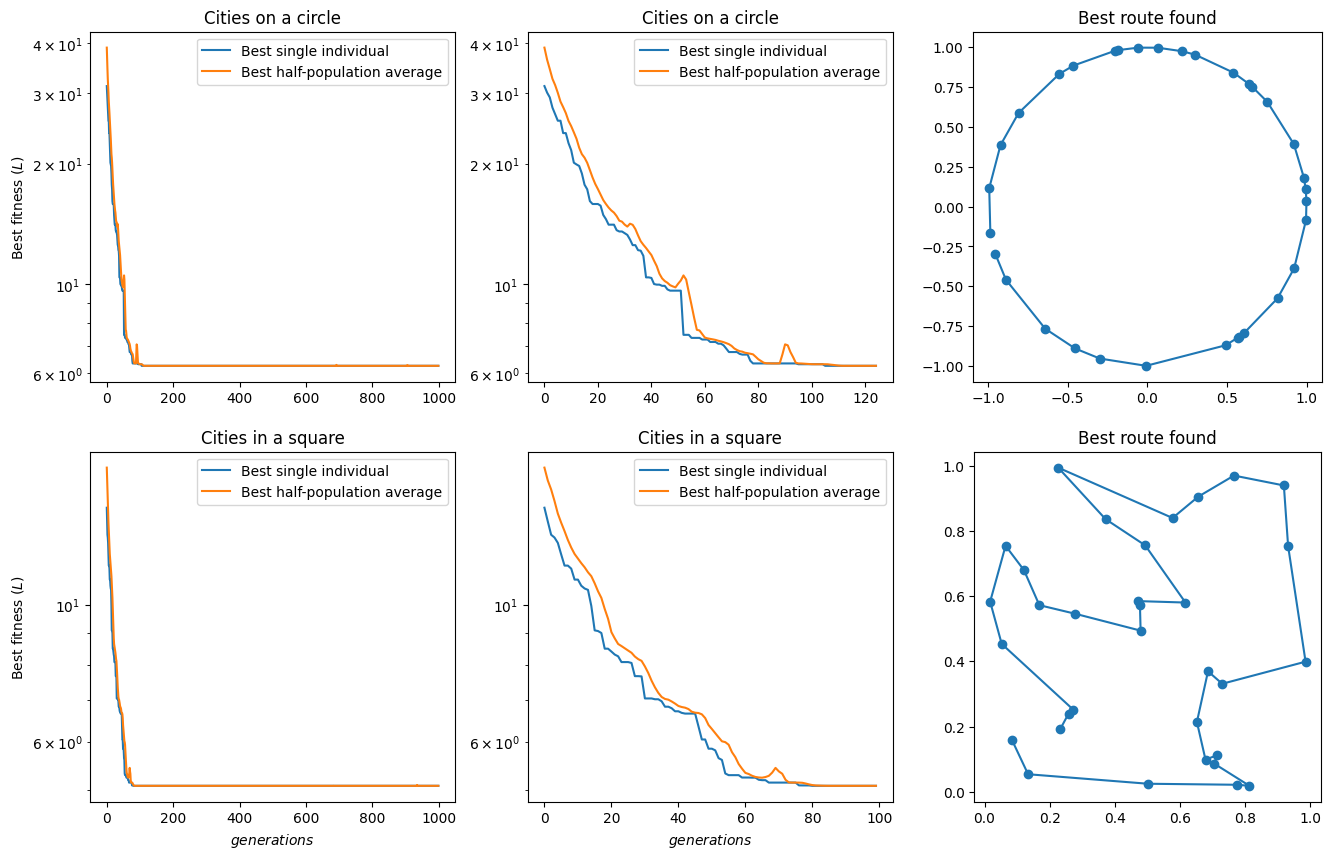

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

results_dir = "sim_results/tsp_genetic"

def load_hist(filename):
    path = f"{results_dir}/{filename}"
    df = pd.read_csv(path, header=0)
    return df.to_numpy(dtype=float)

def load_best(filename):
    path = f"{results_dir}/{filename}"
    df = pd.read_csv(path)
    return df.to_numpy(dtype=float)


circle_hist = load_hist("circle_history.log")
circle_best = load_best("circle_best.log")
square_hist = load_hist("square_history.log")
square_best = load_best("square_best.log")

fig, ax = plt.subplots(2, 3, figsize=(16, 10))

ax[0][0].plot(circle_hist[:, 0], circle_hist[:, 1], label="Best single individual")
ax[0][0].plot(circle_hist[:, 0], circle_hist[:, 2], label="Best half-population average")
ax[0][0].set_title("Cities on a circle")
ax[0][0].set_ylabel(f"Best fitness ($L$)"); ax[0][0].set_yscale("log"); ax[0][0].legend()
ax[0][1].plot(circle_hist[:125, 0], circle_hist[:125, 1], label="Best single individual")
ax[0][1].plot(circle_hist[:125, 0], circle_hist[:125, 2], label="Best half-population average")
ax[0][1].set_title("Cities on a circle")
ax[0][1].set_yscale("log"); ax[0][1].legend()
ax[0][2].plot(circle_best[:, 0], circle_best[:, 1], "o-"); ax[0][2].set_aspect("equal")
ax[0][2].set_title("Best route found")

ax[1][0].set_title("Cities in a square")
ax[1][0].plot(square_hist[:, 0], square_hist[:, 1], label="Best single individual")
ax[1][0].plot(square_hist[:, 0], square_hist[:, 2], label="Best half-population average")
ax[1][0].set_xlabel(f"$generations$"); ax[1][0].set_ylabel(f"Best fitness ($L$)"); ax[1][0].set_yscale("log"); ax[1][0].legend()
ax[1][1].set_title("Cities in a square")
ax[1][1].plot(square_hist[:100, 0], square_hist[:100, 1], label="Best single individual")
ax[1][1].plot(square_hist[:100, 0], square_hist[:100, 2], label="Best half-population average")
ax[1][1].set_xlabel(f"$generations$"); ax[1][1].set_yscale("log"); ax[1][1].legend()
ax[1][2].plot(square_best[:, 0], square_best[:, 1], "o-"); ax[1][2].set_aspect("equal")
ax[1][2].set_title("Best route found")

These results were obtained with $34$ randomly-generated cities for each case, then creating a population of $500$ random routes and running the optimization loop for $1000$ generations.